# Análise da Simulação SWGO — Múon de 5 GeV no WCD
**Dissertação de Mestrado em Física**

Este notebook analisa os dados gerados pela simulação Geant4 de um múon de 5 GeV
atravessando o Water Cherenkov Detector (WCD) do experimento SWGO.

---

## 1. Importações e Configurações

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import numpy as np

# Estilo geral
sns.set_theme(style='whitegrid', palette='pastel')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 13,
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

print('Bibliotecas carregadas com sucesso!')

Bibliotecas carregadas com sucesso!


## 2. Carregamento dos Dados

In [15]:
# Caminho do arquivo CSV gerado pelo Geant4
# O arquivo começa com linhas de cabeçalho iniciadas por '#' que precisamos pular
CSV_PATH = r'\\wsl.localhost\Ubuntu-20.04\home\ubuntu20\geant4-v11.1.3\2026\2026_build\SWGO_muon5GeV_vertical_1000ev_nt_Data.csv'

# Lê o arquivo ignorando as linhas de comentário (#)
df = pd.read_csv(
    CSV_PATH,
    comment='#',
    header=None,
    names=[
        'iEventID',
        'EnergyDeposited_MeV',
        'PositionX_cm',
        'PositionY_cm',
        'PositionZ_cm',
        'Time_ns',
        'EnergyElectronSec_MeV',
        'nElectronSec',
        'nCerenkovByMuon',
        'nCerenkovByElectron',
        'EdepGammas_MeV',
        'EdepTrack_MeV'
    ]
)

print(f'Eventos carregados: {len(df)}')
print(f'\nPrimeiras linhas:')
df.head()

Eventos carregados: 1000

Primeiras linhas:


,iEventID,EnergyDeposited_MeV,PositionX_cm,PositionY_cm,PositionZ_cm,Time_ns,EnergyElectronSec_MeV,nElectronSec,nCerenkovByMuon,nCerenkovByElectron,EdepGammas_MeV,EdepTrack_MeV
0,0,375.029,-0.537015,0.999694,-92.935,6.10276,75.1723,51,60482,7801,0.000000,375.029
1,1,373.776,0.116293,-0.358246,-92.935,6.10236,78.4773,48,61487,9094,0.017107,373.776
2,2,368.381,0.808044,-1.514070,-92.935,6.10357,62.8742,41,60941,8006,0.148983,368.381
3,3,386.993,0.065090,0.320243,-92.935,6.10216,85.6898,44,60674,12180,0.000744,386.993
4,4,423.301,0.016616,-0.064351,-92.935,6.10246,120.8290,38,60669,15194,0.046370,423.301


In [16]:
# Estatísticas básicas
print('=== Estatísticas Descritivas ===')
df.describe().round(3)

=== Estatísticas Descritivas ===


,iEventID,EnergyDeposited_MeV,PositionX_cm,PositionY_cm,PositionZ_cm,Time_ns,EnergyElectronSec_MeV,nElectronSec,nCerenkovByMuon,nCerenkovByElectron,EdepGammas_MeV,EdepTrack_MeV
count,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000
mean,499.500,396.780,-0.038,0.016,-92.935,6.103,112.838,42.172,60886.617,11517.370,0.054,396.780
std,288.819,67.097,0.624,0.620,0.000,0.001,122.709,6.336,246.797,6990.394,0.083,67.097
min,0.000,319.511,-3.118,-2.116,-92.935,6.102,23.465,24.000,60075.000,2185.000,0.000,319.511
25%,249.750,358.251,-0.449,-0.383,-92.935,6.102,58.577,38.000,60721.750,6740.250,0.000,358.251
50%,499.500,378.396,-0.050,0.002,-92.935,6.103,79.532,42.000,60888.500,9539.000,0.009,378.396
75%,749.250,413.340,0.364,0.400,-92.935,6.103,121.136,46.000,61054.000,14760.250,0.091,413.340
max,999.000,1112.560,2.148,3.751,-92.935,6.105,1634.020,63.000,61784.000,65504.000,0.576,1112.560


## 3. Energia Depositada

O múon de 5 GeV é uma **partícula mínimamente ionizante (MIP)** na água.
Esperamos uma distribuição do tipo Landau — assimétrica, com cauda para altos valores,
característica de partículas carregadas relativísticas atravessando um meio material.

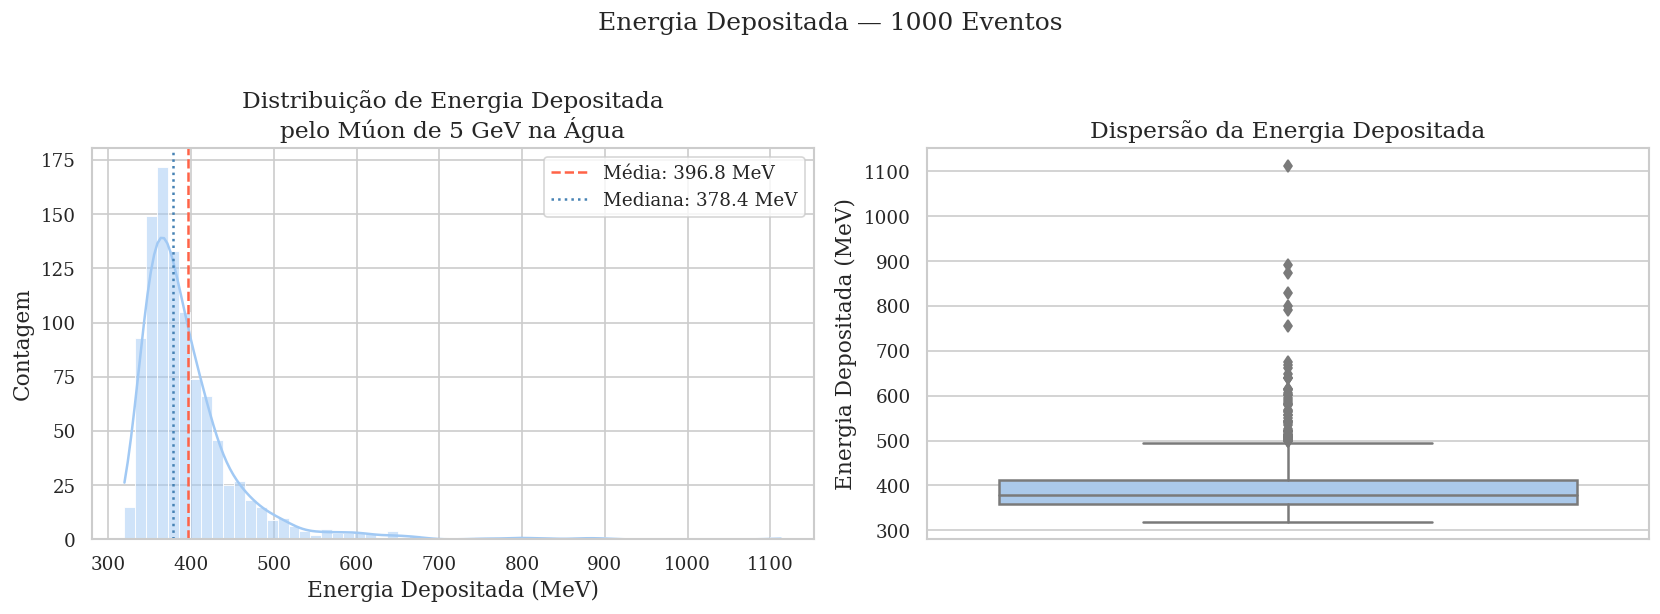

Média: 396.78 MeV
Desvio padrão: 67.10 MeV
Mínimo: 319.51 MeV
Máximo: 1112.56 MeV


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Histograma de energia depositada ---
ax1 = axes[0]
sns.histplot(
    df['EnergyDeposited_MeV'],
    bins=60,
    kde=True,
    color=sns.color_palette('pastel')[0],
    edgecolor='white',
    linewidth=0.5,
    ax=ax1
)
ax1.axvline(df['EnergyDeposited_MeV'].mean(), color='tomato', linestyle='--',
            linewidth=1.5, label=f"Média: {df['EnergyDeposited_MeV'].mean():.1f} MeV")
ax1.axvline(df['EnergyDeposited_MeV'].median(), color='steelblue', linestyle=':',
            linewidth=1.5, label=f"Mediana: {df['EnergyDeposited_MeV'].median():.1f} MeV")
ax1.set_xlabel('Energia Depositada (MeV)')
ax1.set_ylabel('Contagem')
ax1.set_title('Distribuição de Energia Depositada\npelo Múon de 5 GeV na Água')
ax1.legend()

# --- Boxplot ---
ax2 = axes[1]
sns.boxplot(
    y=df['EnergyDeposited_MeV'],
    color=sns.color_palette('pastel')[0],
    ax=ax2
)
ax2.set_ylabel('Energia Depositada (MeV)')
ax2.set_title('Dispersão da Energia Depositada')
ax2.set_xticks([])

plt.suptitle('Energia Depositada — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('energia_depositada.png')
plt.show()
print(f"Média: {df['EnergyDeposited_MeV'].mean():.2f} MeV")
print(f"Desvio padrão: {df['EnergyDeposited_MeV'].std():.2f} MeV")
print(f"Mínimo: {df['EnergyDeposited_MeV'].min():.2f} MeV")
print(f"Máximo: {df['EnergyDeposited_MeV'].max():.2f} MeV")

## 4. Fótons Cherenkov

O número de fótons Cherenkov produzidos é proporcional ao comprimento de trajetória
na água e à carga da partícula. Para o múon, esperamos uma distribuição aproximadamente
gaussiana em torno de um valor médio determinado pela fórmula de Frank-Tamm.

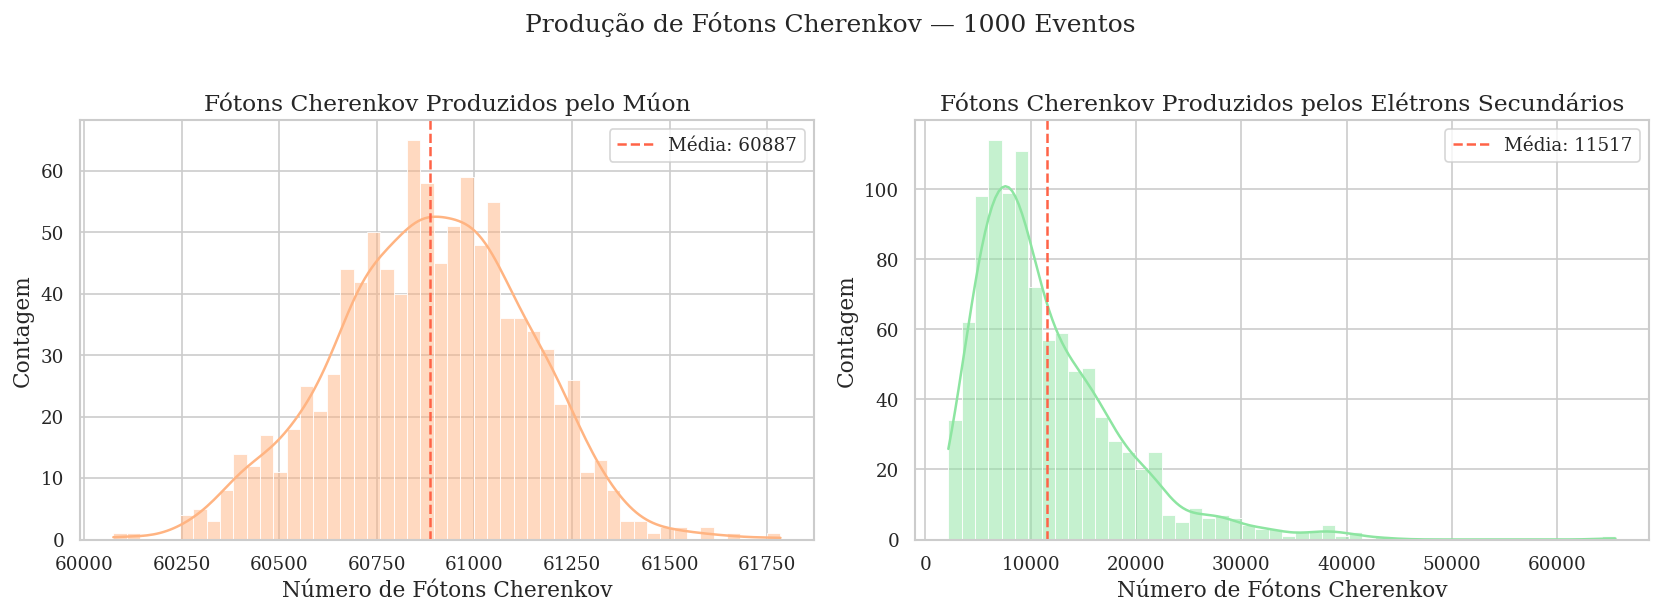

Cherenkov por múon  — Média: 60887 | Std: 247
Cherenkov por e⁻   — Média: 11517 | Std: 6990
Fração por elétrons: 15.9%


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

palette = sns.color_palette('pastel')

# --- Cherenkov pelo múon ---
ax1 = axes[0]
sns.histplot(
    df['nCerenkovByMuon'],
    bins=50,
    kde=True,
    color=palette[1],
    edgecolor='white',
    linewidth=0.5,
    ax=ax1
)
ax1.axvline(df['nCerenkovByMuon'].mean(), color='tomato', linestyle='--',
            linewidth=1.5, label=f"Média: {df['nCerenkovByMuon'].mean():.0f}")
ax1.set_xlabel('Número de Fótons Cherenkov')
ax1.set_ylabel('Contagem')
ax1.set_title('Fótons Cherenkov Produzidos pelo Múon')
ax1.legend()

# --- Cherenkov pelo elétron ---
ax2 = axes[1]
sns.histplot(
    df['nCerenkovByElectron'],
    bins=50,
    kde=True,
    color=palette[2],
    edgecolor='white',
    linewidth=0.5,
    ax=ax2
)
ax2.axvline(df['nCerenkovByElectron'].mean(), color='tomato', linestyle='--',
            linewidth=1.5, label=f"Média: {df['nCerenkovByElectron'].mean():.0f}")
ax2.set_xlabel('Número de Fótons Cherenkov')
ax2.set_ylabel('Contagem')
ax2.set_title('Fótons Cherenkov Produzidos pelos Elétrons Secundários')
ax2.legend()

plt.suptitle('Produção de Fótons Cherenkov — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('cerenkov.png')
plt.show()

print(f"Cherenkov por múon  — Média: {df['nCerenkovByMuon'].mean():.0f} | Std: {df['nCerenkovByMuon'].std():.0f}")
print(f"Cherenkov por e⁻   — Média: {df['nCerenkovByElectron'].mean():.0f} | Std: {df['nCerenkovByElectron'].std():.0f}")
print(f"Fração por elétrons: {df['nCerenkovByElectron'].mean() / (df['nCerenkovByMuon'].mean() + df['nCerenkovByElectron'].mean()) * 100:.1f}%")

## 5. Elétrons Secundários

O múon produz elétrons delta (δ) por ionização (`muIoni`). 
A distribuição do número de elétrons por evento reflete as flutuações
estatísticas do processo de ionização.

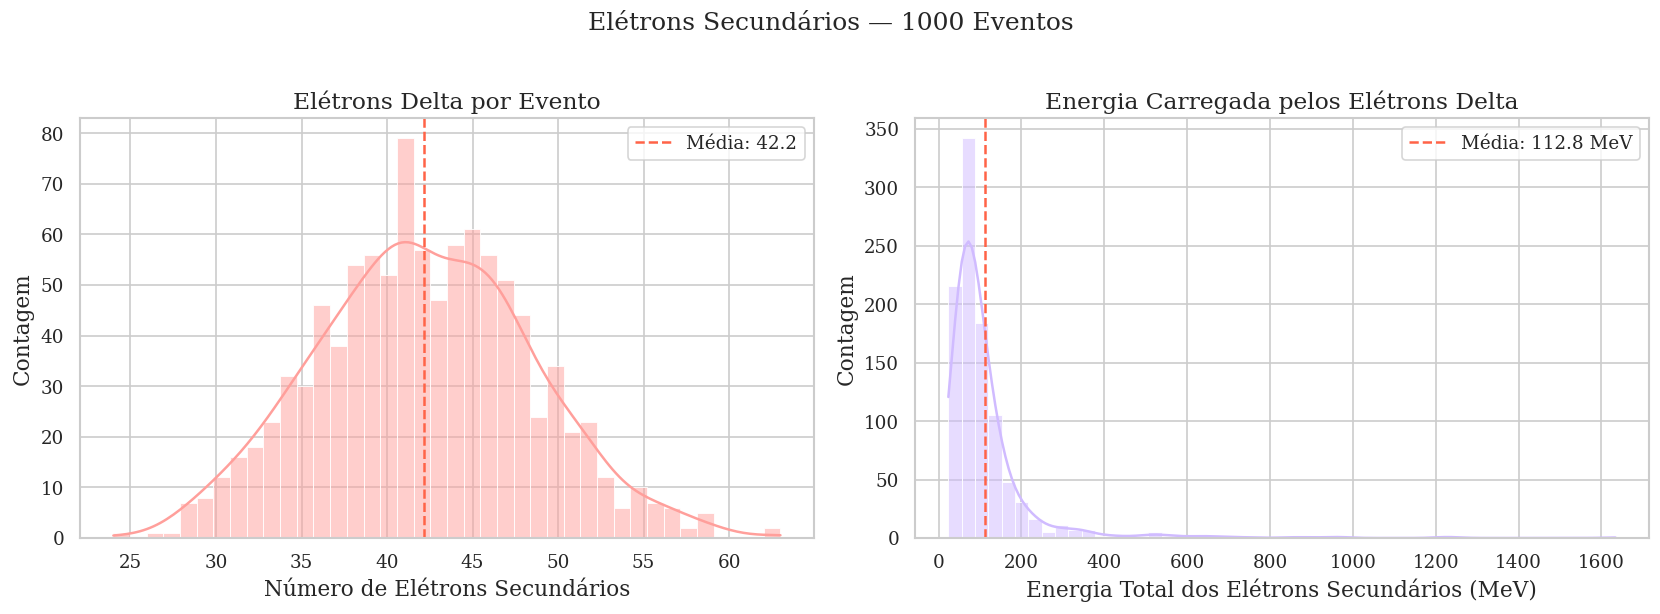

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('pastel')

# --- Número de elétrons secundários ---
ax1 = axes[0]
sns.histplot(
    df['nElectronSec'],
    bins=40,
    kde=True,
    color=palette[3],
    edgecolor='white',
    linewidth=0.5,
    ax=ax1
)
ax1.axvline(df['nElectronSec'].mean(), color='tomato', linestyle='--',
            linewidth=1.5, label=f"Média: {df['nElectronSec'].mean():.1f}")
ax1.set_xlabel('Número de Elétrons Secundários')
ax1.set_ylabel('Contagem')
ax1.set_title('Elétrons Delta por Evento')
ax1.legend()

# --- Energia total dos elétrons secundários ---
ax2 = axes[1]
sns.histplot(
    df['EnergyElectronSec_MeV'],
    bins=50,
    kde=True,
    color=palette[4],
    edgecolor='white',
    linewidth=0.5,
    ax=ax2
)
ax2.axvline(df['EnergyElectronSec_MeV'].mean(), color='tomato', linestyle='--',
            linewidth=1.5, label=f"Média: {df['EnergyElectronSec_MeV'].mean():.1f} MeV")
ax2.set_xlabel('Energia Total dos Elétrons Secundários (MeV)')
ax2.set_ylabel('Contagem')
ax2.set_title('Energia Carregada pelos Elétrons Delta')
ax2.legend()

plt.suptitle('Elétrons Secundários — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('eletrons_secundarios.png')
plt.show()

## 6. Correlações

Relações físicas esperadas entre as variáveis simuladas.

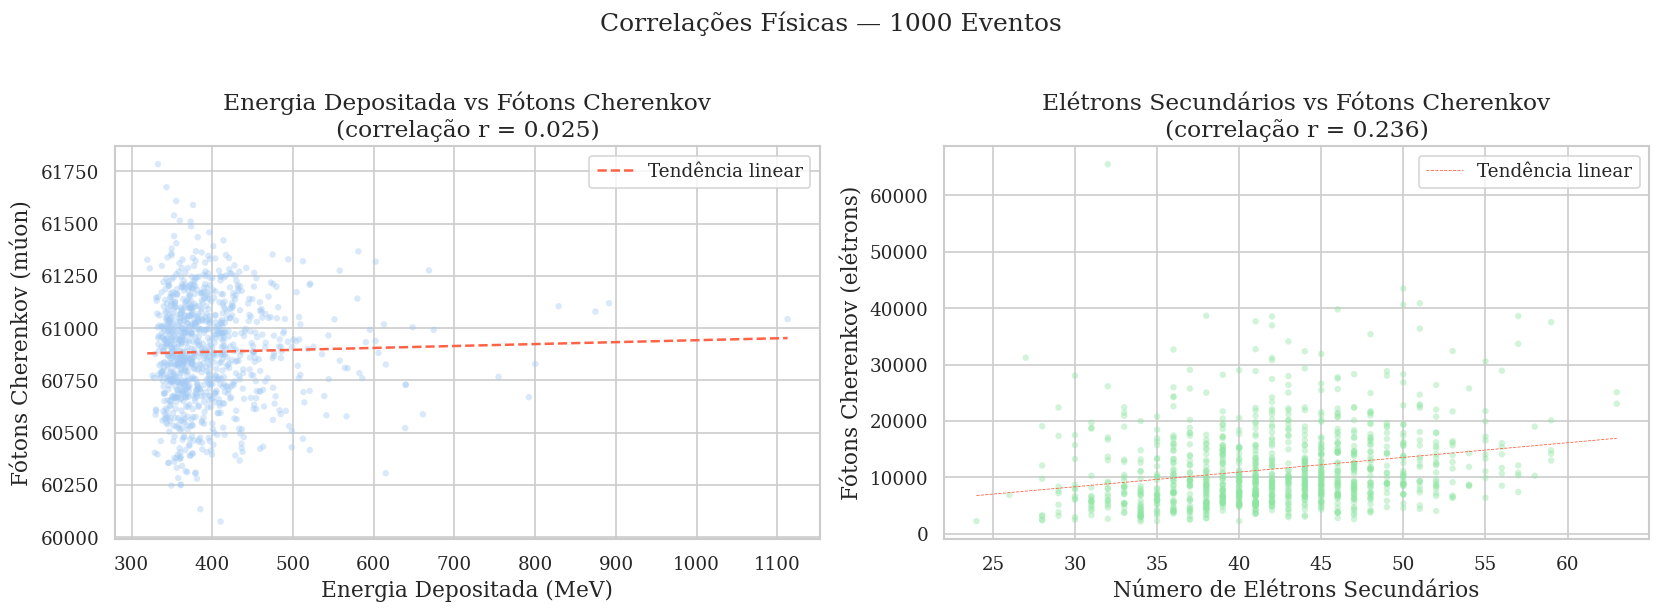

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('pastel')

# --- Energia depositada vs Cherenkov pelo múon ---
ax1 = axes[0]
ax1.scatter(
    df['EnergyDeposited_MeV'],
    df['nCerenkovByMuon'],
    alpha=0.4,
    s=15,
    color=palette[0],
    edgecolors='none'
)
# Linha de tendência
z = np.polyfit(df['EnergyDeposited_MeV'], df['nCerenkovByMuon'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['EnergyDeposited_MeV'].min(), df['EnergyDeposited_MeV'].max(), 100)
ax1.plot(x_line, p(x_line), color='tomato', linewidth=1.5, linestyle='--', label='Tendência linear')
corr1 = df['EnergyDeposited_MeV'].corr(df['nCerenkovByMuon'])
ax1.set_xlabel('Energia Depositada (MeV)')
ax1.set_ylabel('Fótons Cherenkov (múon)')
ax1.set_title(f'Energia Depositada vs Fótons Cherenkov\n(correlação r = {corr1:.3f})')
ax1.legend()

# --- Elétrons secundários vs Cherenkov por elétrons ---
ax2 = axes[1]
ax2.scatter(
    df['nElectronSec'],
    df['nCerenkovByElectron'],
    alpha=0.4,
    s=15,
    color=palette[2],
    edgecolors='none'
)
z2 = np.polyfit(df['nElectronSec'], df['nCerenkovByElectron'], 1)
p2 = np.poly1d(z2)
x_line2 = np.linspace(df['nElectronSec'].min(), df['nElectronSec'].max(), 100)
ax2.plot(x_line2, p2(x_line2), color='tomato', linewidth=0.5, linestyle='--', label='Tendência linear')
corr2 = df['nElectronSec'].corr(df['nCerenkovByElectron'])
ax2.set_xlabel('Número de Elétrons Secundários')
ax2.set_ylabel('Fótons Cherenkov (elétrons)')
ax2.set_title(f'Elétrons Secundários vs Fótons Cherenkov\n(correlação r = {corr2:.3f})')
ax2.legend()

plt.suptitle('Correlações Físicas — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('correlacoes.png')
plt.show()

## 7. Posição Final do Múon

Para um múon vertical entrando pelo centro do tanque,
esperamos X e Y próximos de zero com pequena dispersão
(espalhamento múltiplo), e Z próximo ao fundo do tanque (~-47.5 cm).

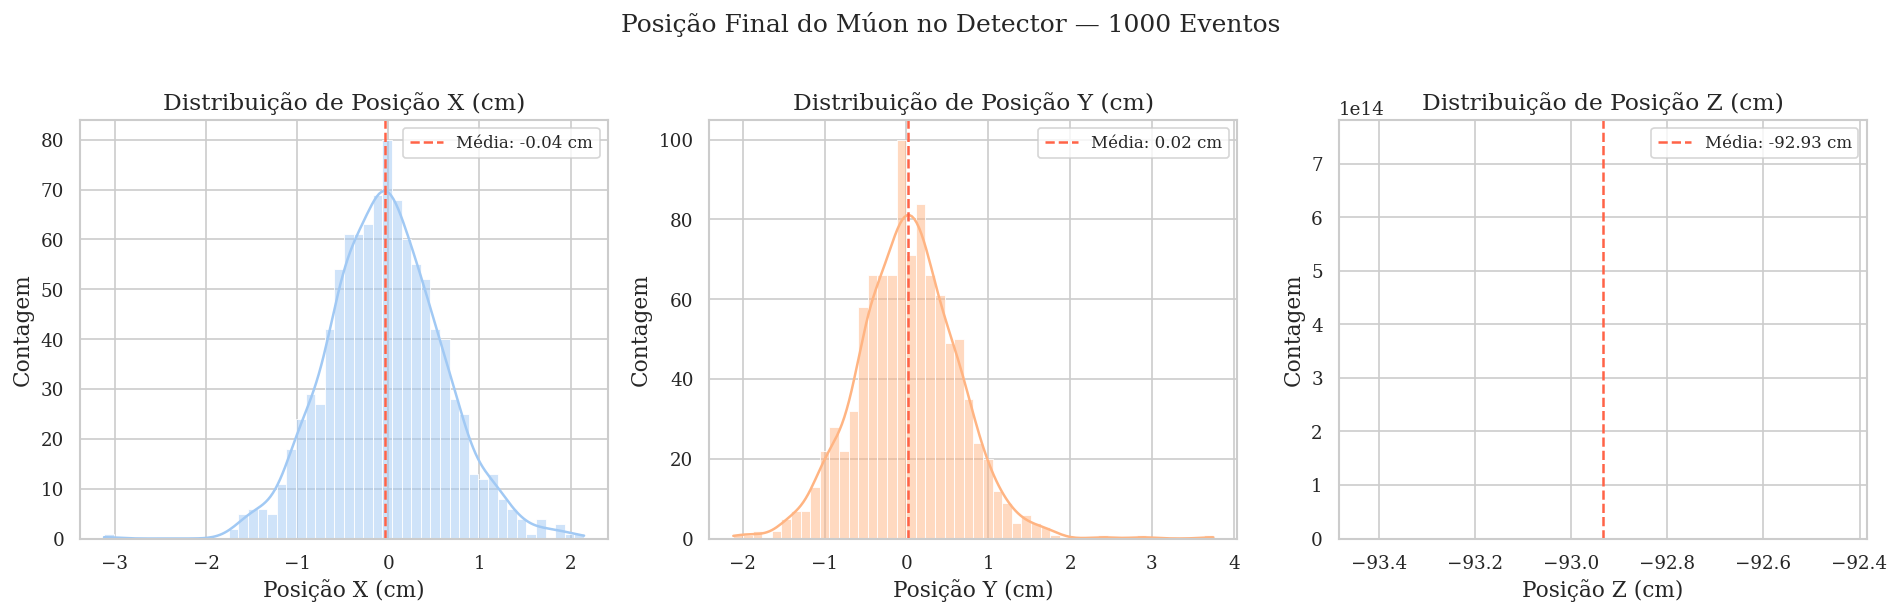

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
palette = sns.color_palette('pastel')
coords = ['PositionX_cm', 'PositionY_cm', 'PositionZ_cm']
labels = ['Posição X (cm)', 'Posição Y (cm)', 'Posição Z (cm)']
colors = [palette[0], palette[1], palette[2]]

for ax, col, label, color in zip(axes, coords, labels, colors):
    sns.histplot(
        df[col],
        bins=50,
        kde=True,
        color=color,
        edgecolor='white',
        linewidth=0.5,
        ax=ax
    )
    ax.axvline(df[col].mean(), color='tomato', linestyle='--',
               linewidth=1.5, label=f'Média: {df[col].mean():.2f} cm')
    ax.set_xlabel(label)
    ax.set_ylabel('Contagem')
    ax.set_title(f'Distribuição de {label}')
    ax.legend(fontsize=10)

plt.suptitle('Posição Final do Múon no Detector — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('posicao_muon.png')
plt.show()

## 8. Mapa XY da Posição Final

Visualização 2D da distribuição espacial das posições finais do múon,
com o círculo representando o limite do volume de água (raio = 170 cm).

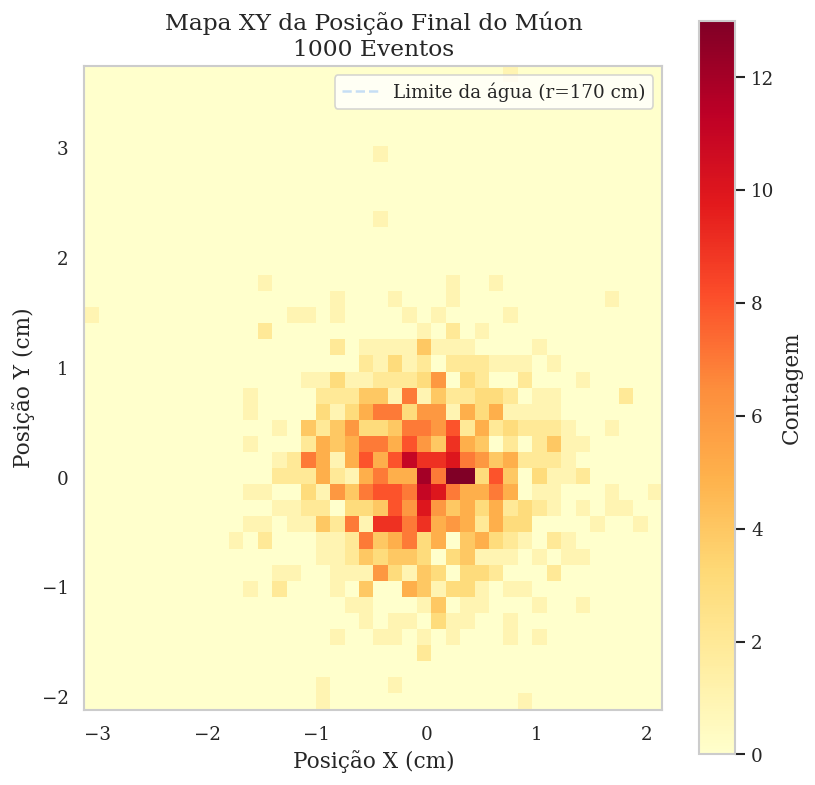

In [22]:
fig, ax = plt.subplots(figsize=(7, 7))

# Mapa de densidade 2D
h = ax.hist2d(
    df['PositionX_cm'],
    df['PositionY_cm'],
    bins=40,
    cmap='YlOrRd'
)
plt.colorbar(h[3], ax=ax, label='Contagem')

# Círculo do limite do tanque
theta = np.linspace(0, 2 * np.pi, 300)
ax.plot(170 * np.cos(theta), 170 * np.sin(theta),
        'b--', linewidth=1.5, alpha=0.6, label='Limite da água (r=170 cm)')

ax.set_xlabel('Posição X (cm)')
ax.set_ylabel('Posição Y (cm)')
ax.set_title('Mapa XY da Posição Final do Múon\n1000 Eventos')
ax.set_aspect('equal')
ax.legend()

plt.tight_layout()
plt.savefig('mapa_xy.png')
plt.show()

## 9. Resumo Físico

Tabela consolidada com os principais resultados da simulação.

In [23]:
resumo = pd.DataFrame({
    'Grandeza': [
        'Energia depositada (MeV)',
        'Fótons Cherenkov (múon)',
        'Fótons Cherenkov (elétrons)',
        'Total fótons Cherenkov',
        'Fração por elétrons (%)',
        'Elétrons secundários (N)',
        'Energia elétrons sec. (MeV)',
        'Deposição por gammas (MeV)',
    ],
    'Média': [
        df['EnergyDeposited_MeV'].mean(),
        df['nCerenkovByMuon'].mean(),
        df['nCerenkovByElectron'].mean(),
        (df['nCerenkovByMuon'] + df['nCerenkovByElectron']).mean(),
        df['nCerenkovByElectron'].mean() / (df['nCerenkovByMuon'] + df['nCerenkovByElectron']).mean() * 100,
        df['nElectronSec'].mean(),
        df['EnergyElectronSec_MeV'].mean(),
        df['EdepGammas_MeV'].mean(),
    ],
    'Desvio Padrão': [
        df['EnergyDeposited_MeV'].std(),
        df['nCerenkovByMuon'].std(),
        df['nCerenkovByElectron'].std(),
        (df['nCerenkovByMuon'] + df['nCerenkovByElectron']).std(),
        None,
        df['nElectronSec'].std(),
        df['EnergyElectronSec_MeV'].std(),
        df['EdepGammas_MeV'].std(),
    ]
})

resumo = resumo.round(3)
print('=== Resumo Físico da Simulação ===')
print(f'Partícula: μ⁻ | Energia: 5 GeV | Direção: vertical | Eventos: {len(df)}')
print(f'Detector: WCD SWGO | Água: raio=170cm, altura=95cm | Tyvek')
print()
resumo

=== Resumo Físico da Simulação ===
Partícula: μ⁻ | Energia: 5 GeV | Direção: vertical | Eventos: 1000
Detector: WCD SWGO | Água: raio=170cm, altura=95cm | Tyvek



,Grandeza,Média,Desvio Padrão
0,Energia depositada (MeV),396.780,67.097
1,Fótons Cherenkov (múon),60886.617,246.797
2,Fótons Cherenkov (elétrons),11517.370,6990.394
3,Total fótons Cherenkov,72403.987,7001.341
4,Fração por elétrons (%),15.907,NaN
5,Elétrons secundários (N),42.172,6.336
6,Energia elétrons sec. (MeV),112.838,122.709
7,Deposição por gammas (MeV),0.054,0.083
